In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
data=pd.read_csv('preprocessing.csv')

In [3]:
data.head()

,scholarship_received,placement_status,starting_salary_usd,gpa_or_score,test_score,origin_country_Finland,origin_country_Germany,origin_country_India,origin_country_Ireland,origin_country_Russia,...,visa_status_Schengen Student Visa,visa_status_Student Visa,visa_status_Study Permit,visa_status_Tier 4,post_graduation_visa_OPT,post_graduation_visa_PSW,post_graduation_visa_Post-Study Visa,post_graduation_visa_Work Permit,study_duration,Salary_Bin
0,0,1,0.242883,1.556464,0.679688,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1.0,1
1,1,1,0.219806,-1.488781,0.765584,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0.0,1
2,1,1,0.365432,-0.658260,1.023273,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0.0,2
3,1,0,0.000000,-1.281151,0.336103,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,1
4,1,0,0.000000,-0.589050,-1.210030,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.5,1


In [4]:
data.shape

(4018, 172)

In [5]:
y = data["placement_status"]
X = data.drop("placement_status", axis=1)

In [6]:

# Define features, dropping leaky columns
X = data.drop(["starting_salary_usd", "Salary_Bin"], axis=1)
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)

In [7]:
correlations = pd.concat([X, y], axis=1).corr()['placement_status'].sort_values(ascending=False)
print(correlations.head(30))

placement_status                                            1.000000
field_of_study_Engineering                                  0.045214
destination_city_Vancouver                                  0.035881
destination_city_Birmingham                                 0.035158
destination_country_India                                   0.031925
university_name_Simon Fraser University                     0.027628
university_name_Higher School of Economics                  0.027493
destination_city_Pilani                                     0.026606
language_proficiency_test_IELTS                             0.025285
destination_city_Moscow                                     0.024658
destination_city_Galway                                     0.024257
destination_city_Kingston                                   0.024164
university_name_University of British Columbia              0.023073
destination_city_Mumbai                                     0.023073
destination_city_Manchester       

In [8]:
print(X.columns.tolist())

['scholarship_received', 'gpa_or_score', 'test_score', 'origin_country_Finland', 'origin_country_Germany', 'origin_country_India', 'origin_country_Ireland', 'origin_country_Russia', 'origin_country_South Africa', 'origin_country_United Arab Emirates', 'origin_country_United Kingdom', 'origin_country_United States', 'destination_country_Finland', 'destination_country_Germany', 'destination_country_India', 'destination_country_Ireland', 'destination_country_Russia', 'destination_country_South Africa', 'destination_country_United Arab Emirates', 'destination_country_United Kingdom', 'destination_country_United States', 'destination_city_Abu Dhabi', 'destination_city_Bangalore', 'destination_city_Berlin', 'destination_city_Birmingham', 'destination_city_Boston', 'destination_city_Cambridge', 'destination_city_Cape Town', 'destination_city_Chennai', 'destination_city_Chicago', 'destination_city_Cork', 'destination_city_Delhi', 'destination_city_Dubai', 'destination_city_Dublin', 'destinatio

In [9]:
from sklearn.decomposition import PCA

In [10]:
from sklearn.decomposition import PCA
import pandas as pd

# Apply PCA to retain 95% of the variance
pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

# Check how many components were kept
print("Original shape:", X.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

# Convert PCA result back to DataFrame
X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

# Ensure y is a DataFrame (and reset index to match)
y_df = pd.DataFrame(y).reset_index(drop=True)

# Combine PCA results with target
final_df = pd.concat([X_pca, y_df], axis=1)
print(final_df.head())

Original shape: (4018, 147)
Reduced shape: (4018, 84)
Explained variance ratio: [0.1051526  0.10222717 0.02663651 0.02614604 0.02543495 0.02207555
 0.02146788 0.02127155 0.0204753  0.02028944 0.01984608 0.01820197
 0.01795211 0.01777467 0.01741657 0.01719066 0.01673716 0.01617449
 0.01563489 0.01472546 0.01443987 0.01385056 0.01334301 0.01330738
 0.01310186 0.01298656 0.0127805  0.01265761 0.01249175 0.01211105
 0.0105315  0.01042345 0.01020446 0.00983958 0.00968727 0.00951022
 0.00909573 0.00888779 0.00758314 0.00724223 0.00707334 0.00706795
 0.00696204 0.00689698 0.00685116 0.00673198 0.00670566 0.00667172
 0.00662835 0.00639113 0.00632999 0.00622101 0.00579559 0.00445425
 0.00431895 0.00413345 0.00410291 0.00394939 0.0035066  0.00347774
 0.00328067 0.00320138 0.00316807 0.0031545  0.00311636 0.00279828
 0.0026805  0.00207846 0.001964   0.00180411 0.00169256 0.0016851
 0.00167284 0.00165199 0.00163671 0.00162869 0.0016055  0.00156564
 0.00155304 0.00153769 0.00153448 0.00152942 0.001

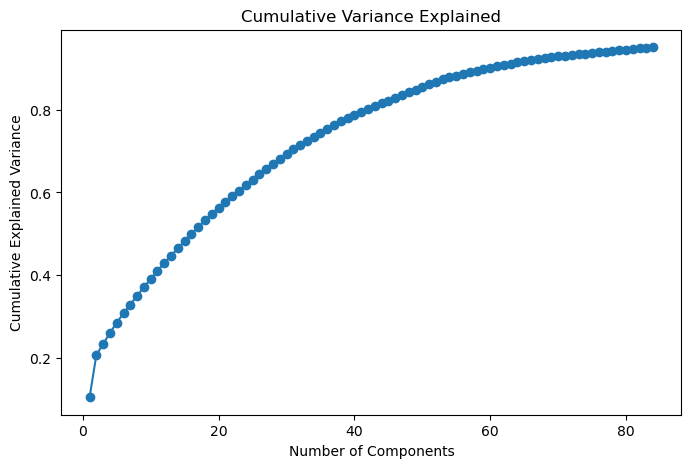

In [11]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
from sklearn.svm import SVC

In [14]:
X_model = X.copy() 
y_model =y.copy()

In [15]:
X_train, X_test, y_train, y_test = train_test_split( X_model, y_model, test_size=0.2, stratify=y_model, random_state=42)

In [16]:
# 4️⃣ Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)

SVC()

In [17]:

svm = SVC(probability=True)



In [18]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score

# ---- Base Model (enable probability for AUC if needed later) ----
svm = SVC(probability=True, random_state=42)

# ---- Grid Search Tuning ----
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_svm.fit(X_train, y_train)

print("Best Parameters (SVM - GridSearchCV):", grid_svm.best_params_)



Best Parameters (SVM - GridSearchCV): {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}


In [19]:
print("Best Cross-Validation Accuracy:", grid_svm.best_score_)
y_pred_svm_grid = grid_svm.best_estimator_.predict(X_test)
print("Test Accuracy (GridSearchCV):", accuracy_score(y_test, y_pred_svm_grid))

Best Cross-Validation Accuracy: 0.5093380425672108
Test Accuracy (GridSearchCV): 0.5236318407960199


In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

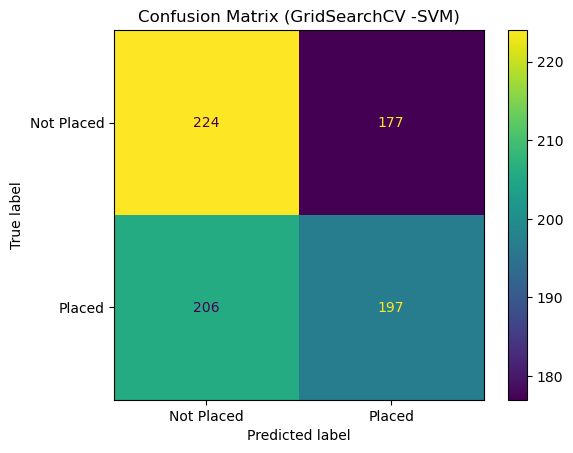

In [21]:

# Confusion Matrix for GridSearchCV SVC Model
cm_grid = confusion_matrix(y_test, y_pred_svm_grid)
disp_grid = ConfusionMatrixDisplay(confusion_matrix=cm_grid, display_labels=['Not Placed', 'Placed'])
disp_grid.plot()
plt.title('Confusion Matrix (GridSearchCV -SVM)')
plt.show()


In [22]:
# ---- Random Search Tuning ----
param_dist_svm = {
    'C': [0.1, 1, 10, 50, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

rand_svm = RandomizedSearchCV(
    estimator=svm,
    param_distributions=param_dist_svm,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
rand_svm.fit(X_train, y_train)

print("\nBest Parameters (SVM - RandomizedSearchCV):", rand_svm.best_params_)



Best Parameters (SVM - RandomizedSearchCV): {'kernel': 'linear', 'gamma': 'auto', 'C': 1}


In [25]:
print("Best Cross-Validation Accuracy:", rand_svm.best_score_)

y_pred_svm_rand = rand_svm.best_estimator_.predict(X_test)
print("Test Accuracy (RandomSearchCV):", accuracy_score(y_test, y_pred_svm_grid))

Best Cross-Validation Accuracy: 0.5062261691932772
Test Accuracy (RandomSearchCV): 0.5236318407960199


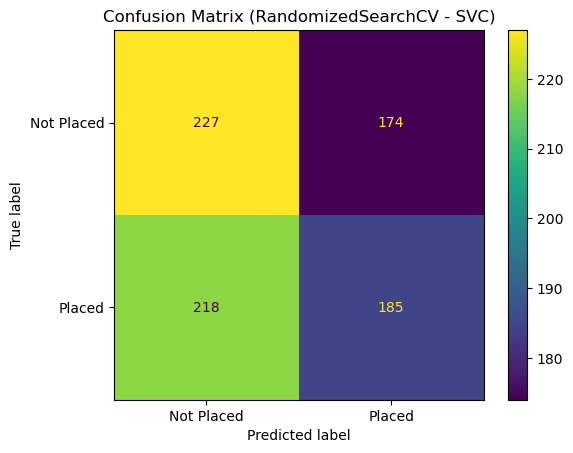

In [27]:
# Confusion Matrix for RandomizedSearchCV SVM Model
cm_random = confusion_matrix(y_test, y_pred_svm_rand)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=['Not Placed', 'Placed'])
disp_random.plot()
plt.title('Confusion Matrix (RandomizedSearchCV - SVC)')
plt.show()

In [34]:
# --- Helper function to get probabilities safely ---
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import roc_auc_score
def get_probabilities(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    else:
        return None

# --- Best models from GridSearchCV and RandomizedSearchCV ---
best_svm_grid = grid_svm.best_estimator_  # make sure grid_svm was run earlier
best_svm_random = rand_svm.best_estimator_

y_pred_svm_grid = best_svm_grid.predict(X_test)
y_prob_svm_grid = get_probabilities(best_svm_grid, X_test)

print("\nGridSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_svm_grid))
print("Precision:", precision_score(y_test, y_pred_svm_grid))
print("Recall   :", recall_score(y_test, y_pred_svm_grid))
print("F1 Score :", f1_score(y_test, y_pred_svm_grid))
if y_prob_svm_grid is not None:
    print("AUC Score:", roc_auc_score(y_test, y_prob_svm_grid))

# --- RandomizedSearchCV ---
y_pred_svm_random = best_svm_random.predict(X_test)
y_prob_svm_random = get_probabilities(best_svm_random, X_test)

print("\nRandomizedSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_svm_random))
print("Precision:", precision_score(y_test, y_pred_svm_random))
print("Recall   :", recall_score(y_test, y_pred_svm_random))
print("F1 Score :", f1_score(y_test, y_pred_svm_random))
if y_prob_svm_random is not None:
    print("AUC Score:", roc_auc_score(y_test, y_prob_svm_random))


GridSearchCV Results:
Accuracy : 0.5236318407960199
Precision: 0.5267379679144385
Recall   : 0.48883374689826303
F1 Score : 0.5070785070785071
AUC Score: 0.5221066440598258

RandomizedSearchCV Results:
Accuracy : 0.5124378109452736
Precision: 0.5153203342618384
Recall   : 0.45905707196029777
F1 Score : 0.48556430446194226
AUC Score: 0.5187774979424887
